In [1]:
import sys
sys.path.append("../src")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from xgboost import XGBRegressor

from features import make_features, FEATURES
from metrics import mae, coverage, avg_width
from calibration import get_correction

df = pd.read_csv("../data/clean_hourly.csv", index_col=0, parse_dates=True)
df = make_features(df)

fit = df.loc[:"2012-03-31"].dropna(subset=FEATURES)
cal = df.loc["2012-04-01":"2012-06-30"]
test = df.loc["2012-07-01":]

print("Fit rows:", len(fit))
print("Calibration rows:", len(cal))
print("Test rows:", len(test))

Fit rows: 10753
Calibration rows: 2184
Test rows: 4416


In [2]:
models = {}

for q in [0.05, 0.5, 0.95]:
    model = XGBRegressor(
        objective="reg:quantileerror",
        quantile_alpha=q,
        n_estimators=300,
        learning_rate=0.05,
        max_depth=5,
        random_state=42,
    )
    model.fit(fit[FEATURES], fit["cnt"])
    models[q] = model
    print("trained quantile", q)

trained quantile 0.05
trained quantile 0.5
trained quantile 0.95


In [3]:
def predict_interval(models, X):
    lower = np.maximum(models[0.05].predict(X), 0)
    median = np.maximum(models[0.5].predict(X), 0)
    upper = np.maximum(models[0.95].predict(X), 0)

    lower = np.minimum(lower, median)
    upper = np.maximum(upper, median)
    return lower, median, upper

In [4]:
lower_cal, median_cal, upper_cal = predict_interval(models, cal[FEATURES])
lower_test, median_test, upper_test = predict_interval(models, test[FEATURES])

print("Coverage on calibration period:", coverage(cal["cnt"], lower_cal, upper_cal))
print("Coverage on test (before fix): ", coverage(test["cnt"], lower_test, upper_test))

Coverage on calibration period: 0.8434065934065934
Coverage on test (before fix):  0.8195199275362319


In [5]:
correction = get_correction(cal["cnt"], lower_cal, upper_cal, alpha=0.1)
print("Correction:", correction)

# widen (or narrow) the interval by the correction
lower_new = np.maximum(lower_test - correction, 0)
upper_new = upper_test + correction

Correction: 26.93450927734375


In [6]:
compare = pd.DataFrame([
    {
        "version": "raw quantile",
        "coverage": coverage(test["cnt"], lower_test, upper_test),
        "avg_width": avg_width(lower_test, upper_test),
    },
    {
        "version": "calibrated",
        "coverage": coverage(test["cnt"], lower_new, upper_new),
        "avg_width": avg_width(lower_new, upper_new),
    },
])
print(compare)
compare.to_csv("../results/interval_results.csv", index=False)

        version  coverage   avg_width
0  raw quantile  0.819520  224.370407
1    calibrated  0.883379  273.511584


In [7]:
out = test[["cnt"]].copy()
out["median"] = median_test
out["lower_raw"] = lower_test
out["upper_raw"] = upper_test
out["lower_cal"] = lower_new
out["upper_cal"] = upper_new
out.to_csv("../results/calibrated_predictions.csv")

          inside_raw  inside_cal
datetime                        
Jul         0.858871    0.905914
Aug         0.869624    0.904570
Sep         0.800000    0.854167
Oct         0.758065    0.829301
Nov         0.784722    0.877778
Dec         0.844086    0.927419


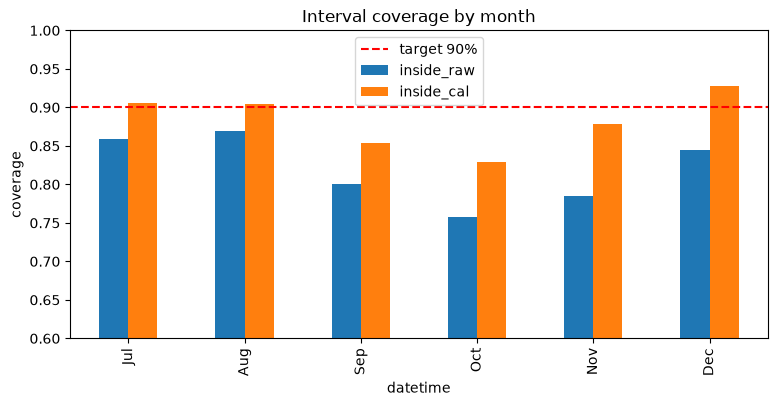

In [8]:
out["inside_raw"] = (out["cnt"] >= out["lower_raw"]) & (out["cnt"] <= out["upper_raw"])
out["inside_cal"] = (out["cnt"] >= out["lower_cal"]) & (out["cnt"] <= out["upper_cal"])

monthly = out[["inside_raw", "inside_cal"]].resample("MS").mean()
monthly.index = monthly.index.strftime("%b")
print(monthly)

monthly.plot(kind="bar", figsize=(9, 4))
plt.axhline(0.9, color="red", linestyle="--", label="target 90%")
plt.ylabel("coverage")
plt.title("Interval coverage by month")
plt.legend()
plt.ylim(0.6, 1.0)
plt.savefig("../results/coverage_by_month.png")
plt.show()

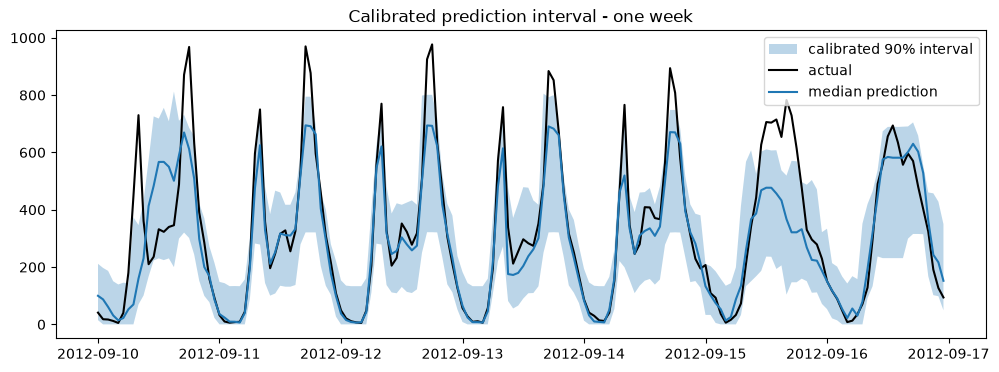

In [9]:
week = out.loc["2012-09-10":"2012-09-16"]

plt.figure(figsize=(12, 4))
plt.fill_between(week.index, week["lower_cal"], week["upper_cal"], alpha=0.3, label="calibrated 90% interval")
plt.plot(week["cnt"], label="actual", color="black")
plt.plot(week["median"], label="median prediction")
plt.legend()
plt.title("Calibrated prediction interval - one week")
plt.savefig("../results/calibrated_week.png")
plt.show()